# Classic SVM — Iris Dataset


## Librerias

In [42]:
# 1. Import all libraries
import pandas as pd
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.preprocessing import MinMaxScaler, label_binarize
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

np.random.seed(42)


## Data

In [ ]:
data = pd.DataFrame(datasets.load_iris().data, columns=datasets.load_iris().feature_names)
data['target'] = datasets.load_iris().target
data

In [ ]:
data.target.unique()

## Data Preparation

In [ ]:
n_qubits = 4

X = data.drop(columns='target')
y = data['target']

# Split test set with a ratio of 0.2
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Custom Dataset Loaded: Train={len(X_train)}, Test={len(X_test)}")

# Normalize to [0, π]
minmax = MinMaxScaler(feature_range=(0, np.pi))
X_train = minmax.fit_transform(X_train)
X_test  = minmax.transform(X_test)
X_test  = np.clip(X_test, 0, np.pi)

print(f"Final shapes -> Train: {X_train.shape}, Test: {X_test.shape}")

## Classic SVM

In [ ]:
class ClassicSVM:
    def __init__(self):
        self.model = SVC(kernel="rbf", random_state=42)
        
    def fit(self, X, y):
        self.model.fit(X, y)
        return self
        
    def predict(self, X):
        return self.model.predict(X)
        
    def decision_function(self, X):
        return self.model.decision_function(X)

## Entrenamiento Classic SVM


In [50]:
# Training and timing statistics
print("=== Train Classic SVM ===")
svm_model = ClassicSVM()
start = time.time()
svm_model.fit(X_train, y_train)
svm_time = time.time() - start
print(f"Classic SVM training time: {svm_time:.2f}s")


=== Train QSVM  ===
QSVM training time: 0.13s

=== Train Classic SVM ===
Classic SVM training time: 0.00s


## Model Evaluation

In [ ]:
def evaluate(model, X_t, y_t, classes):
    preds = model.predict(X_t)
    scores = model.decision_function(X_t)

    acc = accuracy_score(y_t, preds)
    prec = precision_score(y_t, preds, average="macro", zero_division=0)
    rec = recall_score(y_t, preds, average="macro", zero_division=0)
    f1 = f1_score(y_t, preds, average="macro", zero_division=0)
    auc = roc_auc_score(label_binarize(y_t, classes=classes), scores, average="macro")
    return acc, prec, rec, f1, auc, scores, preds

In [52]:
classes = np.unique(y_train)
svm_acc, svm_prec, svm_rec, svm_f1, svm_auc, svm_probs, svm_preds = evaluate(svm_model, X_test, y_test, classes)
print("\n=== Results ===")
print(f"SVM  - Acc: {svm_acc:.4f} | Prec: {svm_prec:.4f} | Rec: {svm_rec:.4f} | F1: {svm_f1:.4f} | AUC: {svm_auc:.4f}")



=== Results Comparison ===
QSVM - Acc: 0.7333 | Prec: 0.7235 | Rec: 0.7276 | F1: 0.7242 | AUC: 0.9060
SVM  - Acc: 1.0000 | Prec: 1.0000 | Rec: 1.0000 | F1: 1.0000 | AUC: 1.0000


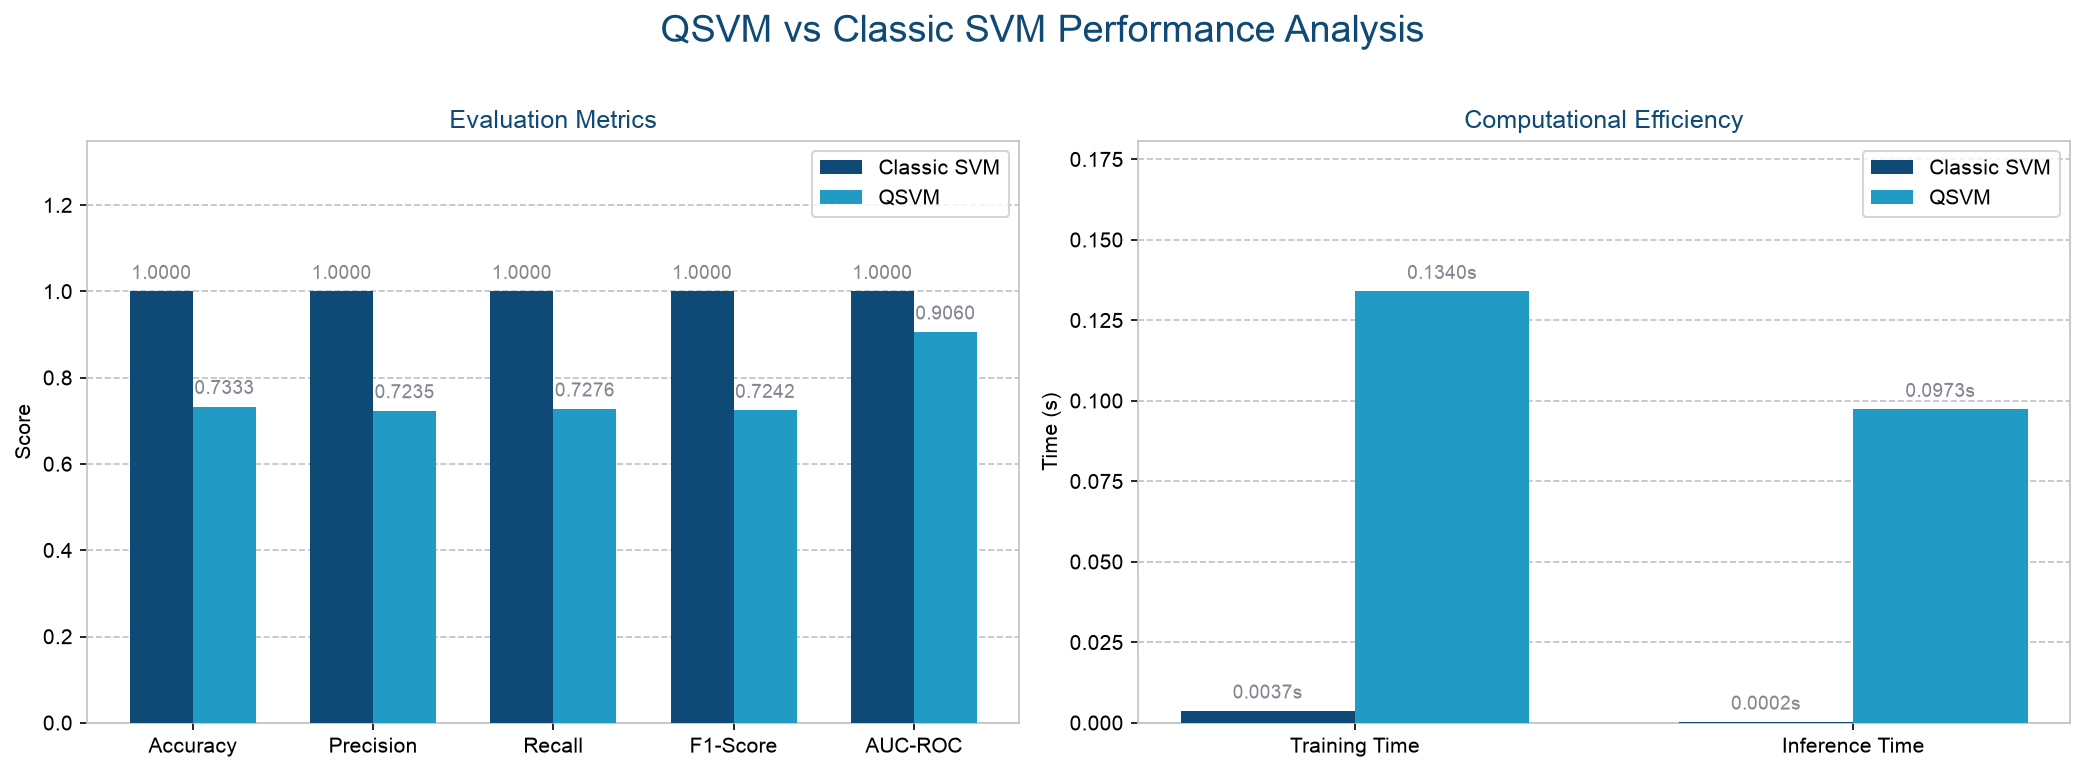

In [53]:
# Result Visualization (multiclase + paleta UNIR)
plt.rcParams.update({
    'font.sans-serif': ['Arial'],
    'axes.edgecolor': '#C0C0C8',
    'grid.color': '#C0C0C8',
    'grid.linestyle': '--'
})

def get_inference_time(model, data):
    start = time.time()
    _ = model.predict(data)
    return time.time() - start

svm_inf_time = get_inference_time(svm_model, X_test)

classical_color = '#0E4A75'  # unirnavy
unir_gris = '#858591'

fig, axs = plt.subplots(1, 2, figsize=(14, 5), dpi=150)
fig.suptitle('Classic SVM Performance Analysis', fontsize=18, y=1.02, color='#0E4A75')

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
svm_vals = [svm_acc, svm_prec, svm_rec, svm_f1, svm_auc]
x = np.arange(len(metrics))
width = 0.5

for i in range(len(metrics)):
    axs[0].bar(x[i], svm_vals[i], width, color=classical_color,
               label='Classic SVM' if i == 0 else '', zorder=3)
    axs[0].text(x[i], svm_vals[i] + 0.02, f'{svm_vals[i]:.4f}',
                ha='center', va='bottom', fontsize=9, color=unir_gris)

axs[0].set_ylabel('Score')
axs[0].set_title('Evaluation Metrics', color='#0E4A75')
axs[0].set_xticks(x)
axs[0].set_xticklabels(metrics)
axs[0].set_ylim(0, 1.35)
axs[0].legend(loc='upper right')
axs[0].grid(axis='y', zorder=0)

eff_labels = ['Training Time', 'Inference Time']
svm_eff = [svm_time, svm_inf_time]
x_eff = np.arange(len(eff_labels))

axs[1].bar(x_eff, svm_eff, width, color=classical_color, label='Classic SVM', zorder=3)
axs[1].set_xticks(x_eff)
axs[1].set_xticklabels(eff_labels)
axs[1].set_ylabel('Time (s)')
axs[1].set_title('Computational Efficiency', color='#0E4A75')
max_time = max(svm_eff)
axs[1].set_ylim(0, max_time * 1.35 if max_time > 0 else 1)
axs[1].legend(loc='upper right')
axs[1].grid(axis='y', zorder=0)

offset = max_time * 0.02 if max_time > 0 else 0.02
for i in range(2):
    axs[1].text(x_eff[i], svm_eff[i] + offset, f'{svm_eff[i]:.4f}s',
                ha='center', va='bottom', fontsize=9, color=unir_gris)

plt.tight_layout()
plt.show()
